# アルゴリズム論Ⅱ 

## 第7回：ニュートン法 (2)（最適化問題への応用・ヘッセ行列・準ニュートン法）

「第5回：最急降下法」では、関数の1階微分（勾配 $\nabla f$）を手がかりに目的関数を最小化するアルゴリズムを学びました。最急降下法は直感的でわかりやすい反面、**「足元の局所的な傾き」しか見ない**ため、谷が細長い関数では激しいジグザグ振動に陥り、解の直前で極めて遅くなる弱点がありました。

一方、「第3回：ニュートン法 (1)」で学んだ求根ニュートン法は、接線を利用して方程式 $f(x) = 0$ の解を驚異的なスピード（二次収束）で突き止める手法でした。

今回学ぶのは、この2つが美しく融合した **「最適化におけるニュートン法（Newton's Method in Optimization）」** です！

---

### 方程式の解法から「最適化」への華麗なる転身
微積分学において、滑らかな関数の極小値（最小値）を探す問題は、**「勾配ベクトルがゼロになる停留点を求める問題（$\nabla f(\mathbf{x}) = \mathbf{0}$）」** に帰着されます。

つまり、第3回の求根ニュートン法を「連立方程式 $\nabla f(\mathbf{x}) = \mathbf{0}$」に適用したものが、最適化におけるニュートン法です。

```
【第3回：求根ニュートン法】
  方程式 f(x) = 0 を解く
  → 接線（1次近似）の根を探す
  → 更新式: x_{k+1} = x_k - f(x_k) / f'(x_k)

【第7回：最適化ニュートン法】
  最適化問題 min f(x)（停留点 ∇f(x) = 0）を解く
  → 放物面（2次近似）の頂点（底）を探す
  → 更新式: x_{k+1} = x_k - [∇²f(x_k)]⁻¹ ∇f(x_k)
```

ここで中心的な役割を果たすのが、関数の「曲率（お椀の曲がり具合）」を表現する **ヘッセ行列（Hessian Matrix）** です。  
ニュートン法は、現在地を放物面（二次曲面）で近似し、その底へ一気にジャンプするため、**適切な条件下ではわずか 1〜数ステップで最適解に到達** します。

---

### ニュートン法・準ニュートン法のアルゴリズムをアニメーションで学ぶ

ヘッセ行列の曲率情報・2次収束の爆発力・鞍点トラップ・特異点クラッシュ・BFGSのセカント学習を直感的に確認できるHTML 3Dアニメーション教材を用意しています：

- ローカルファイル: [newton2.html](newton2.html)
- Web公開版: [https://kita-toshihiro.github.io/algoII/newton2.html](https://kita-toshihiro.github.io/algoII/newton2.html)

---
## 1. 原理と数理的仕組み：ヘッセ行列を用いた2次近似

### 1変数での直感：傾きだけでなく「曲がり具合」を見る
1変数関数 $f(x)$ の現在地 $x_k$ の周辺を、2次のテイラー展開（放物線）で近似してみましょう：

$$
f(x_k + p) \approx q(p) = f(x_k) + f'(x_k) p + \frac{1}{2} f''(x_k) p^2
$$

ここで $p$ は現在地からの移動量（ステップ）です。  
この2次関数 $q(p)$ が最小値をとる場所は、微分してゼロとおくことで求まります：

$$
\frac{dq}{dp} = f'(x_k) + f''(x_k) p = 0 \implies p = - \frac{f'(x_k)}{f''(x_k)}
$$

したがって、次の更新点は次のようになります：

$$
x_{k+1} = x_k - \frac{f'(x_k)}{f''(x_k)}
$$

- $f'(x_k)$：足元の **傾き（坂の急さ）**
- $f''(x_k)$：足元の **曲率（お椀の曲がり具合・カーブのきつさ）**

最急降下法では歩幅（学習率 $\eta$）を人間が勘で調整しなければなりませんでしたが、ニュートン法では **曲率 $f''(x_k)$ が最適な歩幅を自動的に教えてくれる** のです！

---

### 2変数関数への拡張：勾配ベクトルとヘッセ行列
2つのパラメータ $\mathbf{x} = \begin{bmatrix} x \\ y \end{bmatrix}$ を持つ関数 $f(x, y)$ を考えます。

#### 1. 勾配ベクトル（Gradient Vector: 1階偏微分）
坂の傾きを表すベクトルです：
$$
\nabla f(\mathbf{x}) = \begin{bmatrix}
\frac{\partial f}{\partial x} \\
\frac{\partial f}{\partial y}
\end{bmatrix}
$$

#### 2. ヘッセ行列（Hessian Matrix: 2階偏微分）
あらゆる方向への「お椀の曲がり具合」をまとめた $2 \times 2$ 行列です：
$$
H(\mathbf{x}) = \begin{bmatrix}
\frac{\partial^2 f}{\partial x^2} & \frac{\partial^2 f}{\partial x \partial y} \\
\frac{\partial^2 f}{\partial y \partial x} & \frac{\partial^2 f}{\partial y^2}
\end{bmatrix}
$$

一般に偏微分の順序は交換できるため（$\frac{\partial^2 f}{\partial x \partial y} = \frac{\partial^2 f}{\partial y \partial x}$）、**ヘッセ行列は常に対称行列（$H = H^T$）** となります。

---

### ニュートン法の更新式
多次元における2次近似曲面の底（最小点）を求める方程式は：

$$
H(\mathbf{x}_k) \mathbf{p} = - \nabla f(\mathbf{x}_k)
$$

ヘッセ行列の逆行列 $H^{-1}$ を両辺にかけることで、**ニュートン方向 $\mathbf{p}_N$** が得られます：

$$
\mathbf{p}_N = - [H(\mathbf{x}_k)]^{-1} \nabla f(\mathbf{x}_k)
$$

$$
\mathbf{x}_{k+1} = \mathbf{x}_k - [H(\mathbf{x}_k)]^{-1} \nabla f(\mathbf{x}_k)
$$

> **💡 最急降下法とニュートン法の違い**  
> - **最急降下法（1次法）**: $\mathbf{x}_{k+1} = \mathbf{x}_k - \eta \nabla f(\mathbf{x}_k)$  
>   足元の傾きだけを見て、一定割合 $\eta$ だけ下る。お椀が細長いとジグザグ振動する。
> - **ニュートン法（2次法）**: $\mathbf{x}_{k+1} = \mathbf{x}_k - H^{-1} \nabla f(\mathbf{x}_k)$  
>   お椀の歪みをヘッセ行列 $H$ で補正し、お椀の一番底へ最短距離で一気にジャンプする！

---
## 2. ナイーブな基本実装と動作検証（二次関数と1ステップ解法）

まずは、手計算でも追えるシンプルな2変数二次関数を用いて、ニュートン法を実装し、最急降下法と挙動を比較してみましょう。

### 検証モデル：縦横の曲率が異なる楕円谷
以下の二次関数を最小化します：

$$
f(x, y) = x^2 + 5y^2
$$

- 勾配ベクトル：
  $$
  \nabla f(x, y) = \begin{bmatrix} 2x \\ 10y \end{bmatrix}
  $$
- ヘッセ行列：
  $$
  H(x, y) = \begin{bmatrix} 2 & 0 \\ 0 & 10 \end{bmatrix}
  $$
  対角成分を見ると、$x$ 方向の曲率は $2$、$y$ 方向の曲率は $10$（5倍急カーブ）です。
- 解析的最適解：$(x^*, y^*) = (0, 0)$

初期値を $(x_0, y_0) = (8.0, 4.0)$ として、最急降下法とニュートン法を実行します。

=== ニュートン法 vs 最急降下法 の探索ステップ ===
初期点:              (x, y) = (8.00, 4.00), f = 144.00
ニュートン法 Step 1: (x, y) = (0.000000, 0.000000), f = 0.000000e+00
最急降下法 Step 20:  (x, y) = (0.006383, 0.000004), f = 4.074763e-05


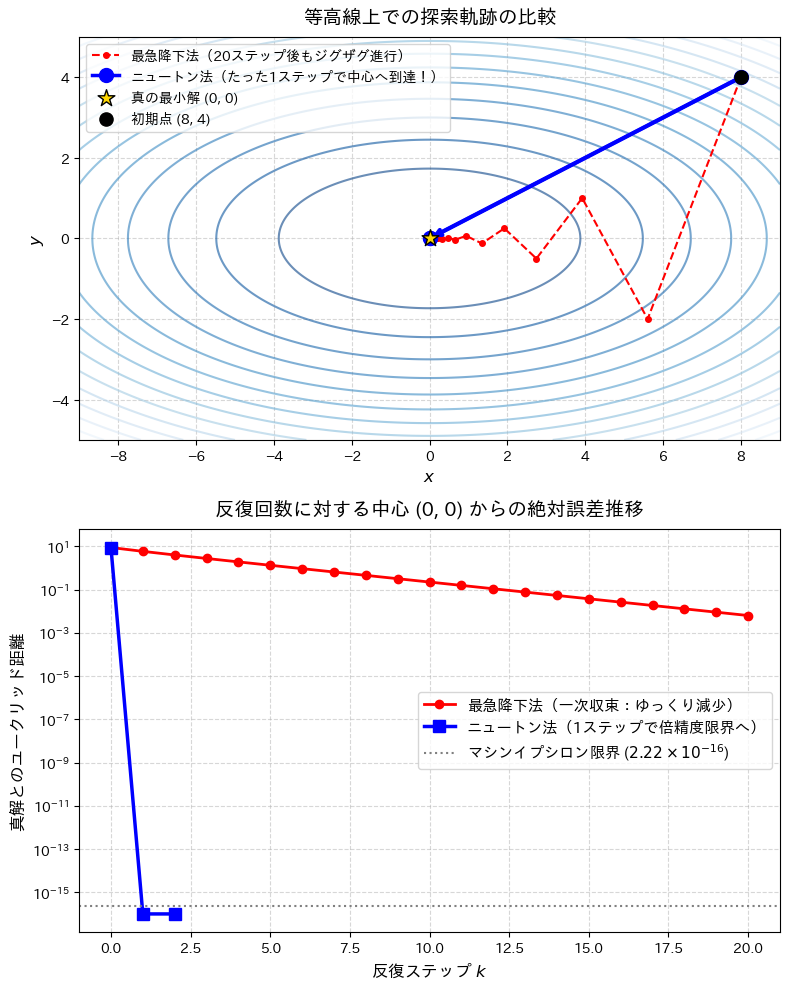

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 1. 目的関数・勾配・ヘッセ行列の定義
def f(v):
    x, y = v[0], v[1]
    return x**2 + 5.0 * y**2

def grad_f(v):
    x, y = v[0], v[1]
    return np.array([2.0 * x, 10.0 * y], dtype=np.float64)

def hess_f(v):
    return np.array([[2.0, 0.0], [0.0, 10.0]], dtype=np.float64)

# 2. ニュートン法の実装
def newton_opt(grad_fn, hess_fn, x0, max_iter=5):
    x = np.array(x0, dtype=np.float64)
    history = [x.copy()]
    for k in range(max_iter):
        g = grad_fn(x)
        H = hess_fn(x)
        # H p = -g を解く
        p = np.linalg.solve(H, -g)
        x = x + p
        history.append(x.copy())
        if np.linalg.norm(g) < 1e-12:
            break
    return x, history

# 3. 最急降下法の実装（比較用）
def gradient_descent(grad_fn, x0, eta=0.15, max_iter=20):
    x = np.array(x0, dtype=np.float64)
    history = [x.copy()]
    for k in range(max_iter):
        g = grad_fn(x)
        x = x - eta * g
        history.append(x.copy())
    return x, history

# 実行
x0 = np.array([8.0, 4.0])
x_nt, hist_nt = newton_opt(grad_f, hess_f, x0)
x_gd, hist_gd = gradient_descent(grad_f, x0, eta=0.15, max_iter=20)

print("=== ニュートン法 vs 最急降下法 の探索ステップ ===")
print(f"初期点:              (x, y) = ({x0[0]:.2f}, {x0[1]:.2f}), f = {f(x0):.2f}")
print(f"ニュートン法 Step 1: (x, y) = ({hist_nt[1][0]:.6f}, {hist_nt[1][1]:.6f}), f = {f(hist_nt[1]):.6e}")
print(f"最急降下法 Step 20:  (x, y) = ({hist_gd[-1][0]:.6f}, {hist_gd[-1][1]:.6f}), f = {f(hist_gd[-1]):.6e}")

# 可視化：縦配置 2 パネル
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10))

# 上図：等高線と軌跡
x_grid = np.linspace(-9, 9, 300)
y_grid = np.linspace(-5, 5, 300)
X, Y = np.meshgrid(x_grid, y_grid)
Z = X**2 + 5.0 * Y**2

ax1.contour(X, Y, Z, levels=15, cmap='Blues_r', alpha=0.6)

gd_pts = np.array(hist_gd)
nt_pts = np.array(hist_nt)

ax1.plot(gd_pts[:, 0], gd_pts[:, 1], 'r.--', lw=1.5, markersize=8, label='最急降下法（20ステップ後もジグザグ進行）')
ax1.plot(nt_pts[:, 0], nt_pts[:, 1], 'b-o', lw=2.5, markersize=10, label='ニュートン法（たった1ステップで中心へ到達！）')
ax1.annotate('', xy=(nt_pts[1, 0], nt_pts[1, 1]), xytext=(nt_pts[0, 0], nt_pts[0, 1]),
             arrowprops=dict(arrowstyle="->", color="blue", lw=3.0))

ax1.scatter([0], [0], color='gold', edgecolor='black', s=160, zorder=6, marker='*', label='真の最小解 (0, 0)')
ax1.scatter([x0[0]], [x0[1]], color='black', s=90, zorder=6, label='初期点 (8, 4)')

ax1.set_title('等高線上での探索軌跡の比較', fontsize=14, pad=10)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('$y$', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10, loc='upper left')

# 下図：中心 (0, 0) からの距離の推移（片対数）
errs_gd = [np.linalg.norm(pt) for pt in hist_gd]
errs_nt = [max(np.linalg.norm(pt), 1e-16) for pt in hist_nt]

ax2.semilogy(range(len(errs_gd)), errs_gd, 'r-o', lw=2, label='最急降下法（一次収束：ゆっくり減少）')
ax2.semilogy(range(len(errs_nt)), errs_nt, 'b-s', lw=2.5, markersize=9, label='ニュートン法（1ステップで倍精度限界へ）')
ax2.axhline(2.22e-16, color='gray', linestyle=':', label='マシンイプシロン限界 ($2.22 \\times 10^{-16}$)')

ax2.set_title('反復回数に対する中心 (0, 0) からの絶対誤差推移', fontsize=14, pad=10)
ax2.set_xlabel('反復ステップ $k$', fontsize=12)
ax2.set_ylabel('真解とのユークリッド距離', fontsize=12)
ax2.grid(True, which='both', linestyle='--', alpha=0.5)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()

---
## 3. 実務での致命的な落とし穴 1：鞍点（サドルポイント）と逆走

二次関数では「たった1ステップ」で解に到達したニュートン法ですが、実務の最適化や機械学習では、そのまま適用できない深刻な落とし穴があります。

その代表例が **「鞍点（サドルポイント）」** です。

### なぜ鞍点や山頂へ向かってしまうのか？
ニュートン法の更新式は、2次近似の **「傾きがゼロになる点」** を探すだけであり、そこが「お椀の底（極小）」なのか「馬の鞍（鞍点）」なのか「山のてっぺん（極大）」なのかを区別しません。

- ヘッセ行列の固有値がすべて正（**正定値**） $\implies$ 綺麗なお椀型（極小点へ向かう ✅）
- ヘッセ行列に負の固有値が含まれる（**不定値・負定値**） $\implies$ 鞍点や山頂（**上り坂へ向かって関数値が増大！ ❌**）
- ヘッセ行列の行列式がゼロ（$\det(H) = 0$） $\implies$ 逆行列が存在せずゼロ除算クラッシュ！

### 実験：鞍点を持つ関数
$$
f(x, y) = x^3 - 3x + y^2
$$
- 極小点：$(1, 0)$（$H = \begin{bmatrix} 6 & 0 \\ 0 & 2 \end{bmatrix}$：正定値 ✅）
- 鞍点：$(-1, 0)$（$H = \begin{bmatrix} -6 & 0 \\ 0 & 2 \end{bmatrix}$：負の固有値 $-6$ を持つ ❌）

$x < 0$ の領域からニュートン法をスタートさせると、極小値ではなく鞍点に向かってジャンプし、最小化のはずが関数値が増加してしまいます。

=== 鞍点領域 (x < 0) からのニュートン法の挙動 ===
Step 1: x = [-1.4500,  0.0000], f(x) =  1.3014 (固有値: -8.7, 2.0)
Step 2: x = [-1.0698,  0.0000], f(x) =  1.9850 (固有値: -6.4, 2.0)
Step 3: x = [-1.0023,  0.0000], f(x) =  2.0000 (固有値: -6.0, 2.0)
Step 4: x = [-1.0000,  0.0000], f(x) =  2.0000 (固有値: -6.0, 2.0)
Step 5: x = [-1.0000,  0.0000], f(x) =  2.0000 (固有値: -6.0, 2.0)
\n=== 特異点 (x = 0) でのゼロ除算テスト ===
⚠️ 期待通り例外を検知: LinAlgError: Singular matrix


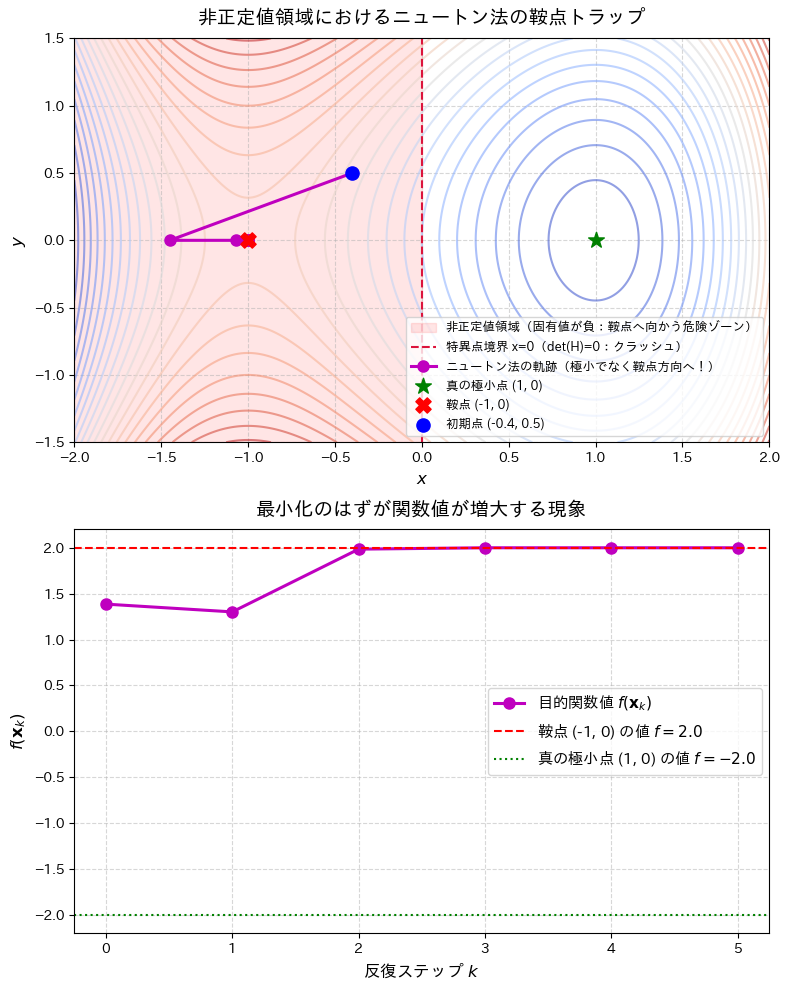

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

def saddle_f(v):
    return v[0]**3 - 3.0 * v[0] + v[1]**2

def saddle_grad(v):
    return np.array([3.0 * v[0]**2 - 3.0, 2.0 * v[1]], dtype=np.float64)

def saddle_hess(v):
    return np.array([[6.0 * v[0], 0.0], [0.0, 2.0]], dtype=np.float64)

# 鞍点領域からの実行
x0 = np.array([-0.4, 0.5])
x = x0.copy()
traj = [x.copy()]
f_vals = [saddle_f(x)]

print("=== 鞍点領域 (x < 0) からのニュートン法の挙動 ===")
for k in range(1, 6):
    g = saddle_grad(x)
    H = saddle_hess(x)
    p = np.linalg.solve(H, -g)
    x = x + p
    traj.append(x.copy())
    f_vals.append(saddle_f(x))
    print(f"Step {k}: x = [{x[0]:7.4f}, {x[1]:7.4f}], f(x) = {saddle_f(x):7.4f} (固有値: {6*x[0]:.1f}, 2.0)")

# 特異点 (det(H) = 0) のテスト
x_singular = np.array([0.0, 1.0])
print("\\n=== 特異点 (x = 0) でのゼロ除算テスト ===")
try:
    np.linalg.solve(saddle_hess(x_singular), -saddle_grad(x_singular))
except np.linalg.LinAlgError as e:
    print(f"⚠️ 期待通り例外を検知: {type(e).__name__}: {e}")

# 可視化：縦配置 2 パネル
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10))

# 上図：等高線と鞍点トラップ
x_vals = np.linspace(-2.0, 2.0, 300)
y_vals = np.linspace(-1.5, 1.5, 300)
X, Y = np.meshgrid(x_vals, y_vals)
Z = X**3 - 3.0 * X + Y**2

ax1.contour(X, Y, Z, levels=20, cmap='coolwarm', alpha=0.6)
ax1.axvspan(-2.0, 0, color='red', alpha=0.1, label='非正定値領域（固有値が負：鞍点へ向かう危険ゾーン）')
ax1.axvline(0, color='crimson', linestyle='--', label='特異点境界 x=0（det(H)=0：クラッシュ）')

t_pts = np.array(traj)
ax1.plot(t_pts[:, 0], t_pts[:, 1], 'm-o', lw=2.2, markersize=8, label='ニュートン法の軌跡（極小でなく鞍点方向へ！）')
ax1.scatter([1.0], [0.0], color='green', s=140, marker='*', zorder=6, label='真の極小点 (1, 0)')
ax1.scatter([-1.0], [0.0], color='red', s=120, marker='X', zorder=6, label='鞍点 (-1, 0)')
ax1.scatter([x0[0]], [x0[1]], color='blue', s=90, zorder=6, label='初期点 (-0.4, 0.5)')

ax1.set_title('非正定値領域におけるニュートン法の鞍点トラップ', fontsize=14, pad=10)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('$y$', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=9, loc='lower right')

# 下図：関数値の推移
ax2.plot(range(len(f_vals)), f_vals, 'm-o', lw=2.2, markersize=8, label=r'目的関数値 $f(\mathbf{x}_k)$')
ax2.axhline(saddle_f(np.array([-1.0, 0.0])), color='red', linestyle='--', label='鞍点 (-1, 0) の値 $f=2.0$')
ax2.axhline(saddle_f(np.array([1.0, 0.0])), color='green', linestyle=':', label='真の極小点 (1, 0) の値 $f=-2.0$')

ax2.set_title('最小化のはずが関数値が増大する現象', fontsize=14, pad=10)
ax2.set_xlabel('反復ステップ $k$', fontsize=12)
ax2.set_ylabel(r'$f(\mathbf{x}_k)$', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()

---
## 4. 実務での致命的な落とし穴 2：計算コストと次元の壁（なぜ深層学習で使えないのか？）

純粋ニュートン法のもう一つの大きな壁は、**「変数の数（次元数 $d$）が増えたときの計算爆発」** です。

### 1ステップに必要な計算コストとメモリ
変数の数が $d$ 個あるとき：

| 項目 | 最急降下法 (1次法) | 純粋ニュートン法 (2次法) |
| :--- | :---: | :---: |
| **微分の計算** | 勾配ベクトル $d$ 個 $\implies O(d)$ | ヘッセ行列 $\approx d^2 / 2$ 個 $\implies O(d^2)$ |
| **1ステップの計算量** | ベクトル加算 $\implies O(d)$ | 連立方程式 $H \mathbf{p} = -\mathbf{g}$ 求解 $\implies \mathbf{O(d^3)}$ |
| **メモリ消費量** | ベクトル1本 $\implies O(d)$ | $d \times d$ 行列保持 $\implies \mathbf{O(d^2)}$ |

- **$d = 100$**:  
  ヘッセ行列の計算量は $100^3 = 100万$ 回程度。パソコンで一瞬（数ミリ秒）で解けます。
- **$d = 10^7 \sim 10^{11}$（ディープラーニング・大規模言語モデルなど）**:  
  ヘッセ行列のメモリだけで **数百テラバイト〜エクサバイト** に達し、1ステップの逆行列計算に数百年かかります！

これが、**「現代のディープラーニングにおいて、ニュートン法ではなく1階微分の勾配降下法（SGDやAdam）が圧倒的に使われている最大の理由」** です。

---
## 5. 準ニュートン法（BFGS）：2階微分なしで曲率を自動学習する

ここまでで、以下のジレンマが浮き彫りになりました：
- **最急降下法**: 計算は軽いが、谷でジグザグして遅い。
- **純粋ニュートン法**: 速いが、2階微分の手計算が大変で、鞍点に弱く、$O(d^3)$ の計算量が重すぎる。

「2階微分を手計算せず、$O(d^3)$ の連立方程式も解かず、それでもニュートン法のように谷を滑らかに下る方法はないか？」

この理想を実現したのが **「準ニュートン法（Quasi-Newton Method）」** です。

---

### セカント条件（割線関係）のアイデア
1歩進んだときの「探索点の変化量 $\mathbf{s}_k$」と「勾配の変化量 $\mathbf{y}_k$」に注目します：

$$
\mathbf{s}_k = \mathbf{x}_{k+1} - \mathbf{x}_k, \quad \mathbf{y}_k = \nabla f(\mathbf{x}_{k+1}) - \nabla f(\mathbf{x}_k)
$$

関数の曲率（ヘッセ行列 $H$）とお椀の傾きの変化には、以下の近似関係が成り立ちます：

$$
H_{k+1} \mathbf{s}_k \approx \mathbf{y}_k \iff \mathbf{s}_k \approx H_{k+1}^{-1} \mathbf{y}_k
$$

これを **セカント条件** と呼びます。

### BFGS法の知恵
準ニュートン法の代表格である **BFGS法** は、逆ヘッセ行列の近似行列 $V_k \approx H_k^{-1}$ を持ち、単位行列 $V_0 = I$（最急降下法）からスタートして、**ステップごとの勾配の変化 $(\mathbf{s}_k, \mathbf{y}_k)$ を積み重ねることで、逆ヘッセ行列を自動的に学習・更新** していきます。

> **🌟 準ニュートン法（BFGS）のメリット**  
> 1. **2階微分が一切不要**（1階の勾配 $\nabla f$ だけで動く）
> 2. **連立方程式の求解が不要**（逆行列 $V_k$ を直接更新するため毎ステップ $O(d^2)$）
> 3. **常に正定値性を自動維持**（鞍点トラップに強く、安全にお椀の底へ向かう）

細く曲がりくねった谷を持つ有名な難関問題 **「Rosenbrock 関数（バナナ谷）」** で、最急降下法と BFGS 法を対決させてみましょう！

=== Rosenbrock 関数における 35 ステップ後の比較 ===
最急降下法: (x, y) = (0.9123, 0.8743), f = 0.184427
BFGS 法:   (x, y) = (1.0000, 1.0000), f = 2.745624e-17


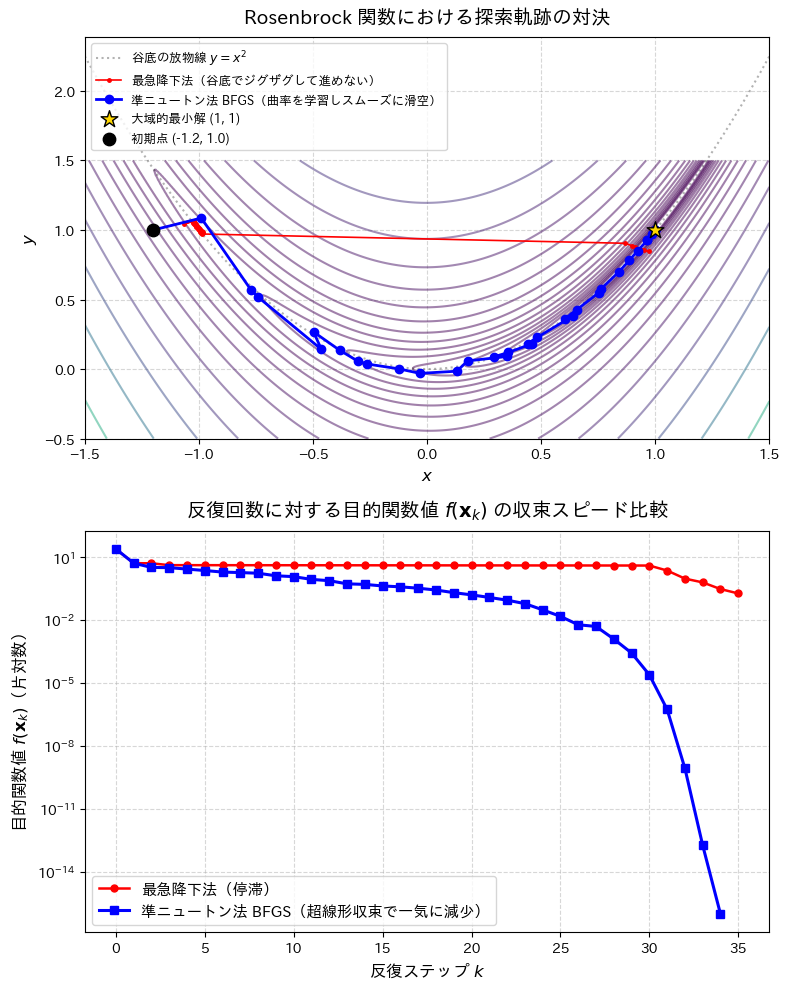

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 1. Rosenbrock関数（バナナ関数）：最小値は (1, 1) で f = 0
def rosenbrock(v):
    x, y = v[0], v[1]
    return 100.0 * (y - x**2)**2 + (1.0 - x)**2

def rosenbrock_grad(v):
    x, y = v[0], v[1]
    dfdx = -400.0 * x * (y - x**2) - 2.0 * (1.0 - x)
    dfdy = 200.0 * (y - x**2)
    return np.array([dfdx, dfdy], dtype=np.float64)

# 2. 直線探索（Armijo法）
def line_search(f, grad_fn, x, p):
    alpha = 1.0
    c1 = 1e-4
    rho = 0.5
    fx = f(x)
    gx = grad_fn(x)
    while f(x + alpha * p) > fx + c1 * alpha * np.dot(gx, p):
        alpha *= rho
        if alpha < 1e-12:
            break
    return alpha

# 3. 準ニュートン法（BFGS）の実装
def bfgs(f, grad_fn, x0, max_iter=40):
    x = np.array(x0, dtype=np.float64)
    d = len(x)
    V = np.eye(d)  # 逆ヘッセ行列の初期推定 V0 = I
    history = [x.copy()]
    
    for k in range(max_iter):
        g = grad_fn(x)
        if np.linalg.norm(g) < 1e-6:
            break
        p = -V @ g  # 探索方向
        alpha = line_search(f, grad_fn, x, p)
        s = alpha * p
        x_next = x + s
        y = grad_fn(x_next) - g
        
        # BFGS 更新式
        ys = np.dot(y, s)
        if ys > 1e-10:
            rho_k = 1.0 / ys
            I = np.eye(d)
            V = (I - rho_k * np.outer(s, y)) @ V @ (I - rho_k * np.outer(y, s)) + rho_k * np.outer(s, s)
            
        x = x_next
        history.append(x.copy())
    return x, history

# 4. 最急降下法（直線探索付き）
def gd_linesearch(f, grad_fn, x0, max_iter=40):
    x = np.array(x0, dtype=np.float64)
    history = [x.copy()]
    for k in range(max_iter):
        g = grad_fn(x)
        if np.linalg.norm(g) < 1e-6:
            break
        p = -g
        alpha = line_search(f, grad_fn, x, p)
        x = x + alpha * p
        history.append(x.copy())
    return x, history

# 初期値設定
x0 = np.array([-1.2, 1.0])
x_bfgs, hist_bfgs = bfgs(rosenbrock, rosenbrock_grad, x0, max_iter=35)
x_gd, hist_gd = gd_linesearch(rosenbrock, rosenbrock_grad, x0, max_iter=35)

print("=== Rosenbrock 関数における 35 ステップ後の比較 ===")
print(f"最急降下法: (x, y) = ({x_gd[0]:.4f}, {x_gd[1]:.4f}), f = {rosenbrock(x_gd):.6f}")
print(f"BFGS 法:   (x, y) = ({x_bfgs[0]:.4f}, {x_bfgs[1]:.4f}), f = {rosenbrock(x_bfgs):.6e}")

# 可視化：縦配置 2 パネル
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10))

# 上図：バナナ谷の等高線と軌跡
x_vals = np.linspace(-1.5, 1.5, 300)
y_vals = np.linspace(-0.5, 1.5, 300)
X, Y = np.meshgrid(x_vals, y_vals)
Z = 100.0 * (Y - X**2)**2 + (1.0 - X)**2

ax1.contour(X, Y, Z, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.5)
ax1.plot(x_vals, x_vals**2, 'k:', alpha=0.3, label='谷底の放物線 $y = x^2$')

gd_p = np.array(hist_gd)
bfgs_p = np.array(hist_bfgs)

ax1.plot(gd_p[:, 0], gd_p[:, 1], 'r.-', lw=1.2, markersize=5, label='最急降下法（谷底でジグザグして進めない）')
ax1.plot(bfgs_p[:, 0], bfgs_p[:, 1], 'b-o', lw=2.0, markersize=6, label='準ニュートン法 BFGS（曲率を学習しスムーズに滑空）')
ax1.scatter([1], [1], color='gold', edgecolor='black', s=160, zorder=6, marker='*', label='大域的最小解 (1, 1)')
ax1.scatter([x0[0]], [x0[1]], color='black', s=80, zorder=6, label='初期点 (-1.2, 1.0)')

ax1.set_title('Rosenbrock 関数における探索軌跡の対決', fontsize=14, pad=10)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('$y$', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=9, loc='upper left')

# 下図：関数値の減少スピード比較
f_gd = [rosenbrock(pt) for pt in hist_gd]
f_bfgs = [max(rosenbrock(pt), 1e-16) for pt in hist_bfgs]

ax2.semilogy(range(len(f_gd)), f_gd, 'r-o', lw=1.8, markersize=5, label='最急降下法（停滞）')
ax2.semilogy(range(len(f_bfgs)), f_bfgs, 'b-s', lw=2.2, markersize=6, label='準ニュートン法 BFGS（超線形収束で一気に減少）')

ax2.set_title(r'反復回数に対する目的関数値 $f(\mathbf{x}_k)$ の収束スピード比較', fontsize=14, pad=10)
ax2.set_xlabel('反復ステップ $k$', fontsize=12)
ax2.set_ylabel(r'目的関数値 $f(\mathbf{x}_k)$（片対数）', fontsize=12)
ax2.grid(True, which='both', linestyle='--', alpha=0.5)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()

<div style="font-size: 88%; color: #374151; background-color: #f9fafb; padding: 10px 14px; border-left: 4px solid #9ca3af; border-radius: 4px; margin-top: 6px;">

**💡（補足）なぜ最急降下法に「直線探索（Line Search）」を付けているのか？**
- **直線探索とは**：進む方向を決めた後、関数値が確実に下がるよう「歩幅 $\alpha$ を地形に合わせて自動調整する技術」です（ここでは歩幅を半分ずつ縮める Armijo バックトラッキング法を採用）。
- **なぜ必要なのか**：Rosenbrock 関数は「谷の壁が崖のように急峻で、谷底は極めて平坦」です。固定の学習率 $\eta$ では、崖で跳ね飛んで即座に発散（オーバーフロー）するか、平坦な谷底で歩幅が小さすぎて停止するかの極端な二者択一になり、比較実験が成立しません。
- **教育的意図**：歩幅を自動調整するサポートを与えて最急降下法を「ベストな状態」にしても、進む方向が足元の傾き（1次情報）だけである以上、谷底でジグザグ停滞します。これにより、曲率（2次情報）を自己学習してスムーズに滑空する BFGS 法の優位性が公平かつ鮮明に分かります。

</div>

---
## 6. 体系的実験と可視化対決：一次収束 vs 超線形収束 vs 二次収束

アルゴリズムの性能差を、数学的な「収束次数」の観点から整理してみましょう。

1. **一次収束（最急降下法）**:  
   ステップごとに誤差が一定の割合（例: 毎歩 10% ずつ）で減る。片対数グラフでは「右下がりの直線」になる。
2. **超線形収束（準ニュートン法 BFGS）**:  
   ステップが進むほど誤差の縮小ペースが加速していく。片対数グラフでは「下に折れ曲がって急降下」する。
3. **二次収束（純粋ニュートン法）**:  
   **反復ごとに正しい有効桁数が約2倍になる！**  
   （誤差が $10^{-2} \to 10^{-4} \to 10^{-8} \to 10^{-16}$ とわずか3ステップでマシンの限界へ突き刺さる）。

Python の標準的な科学計算ライブラリ `scipy.optimize.minimize(method='BFGS')` も交えて、収束スピードを直接対決させます。

=== 収束精度の比較対決 ===
最急降下法 (25反復後): 誤差 = 1.1326e-05
SciPy BFGS (7反復後): 誤差 = 1.0000e-16
純粋ニュートン法 (1反復後): 誤差 = 1.0000e-16


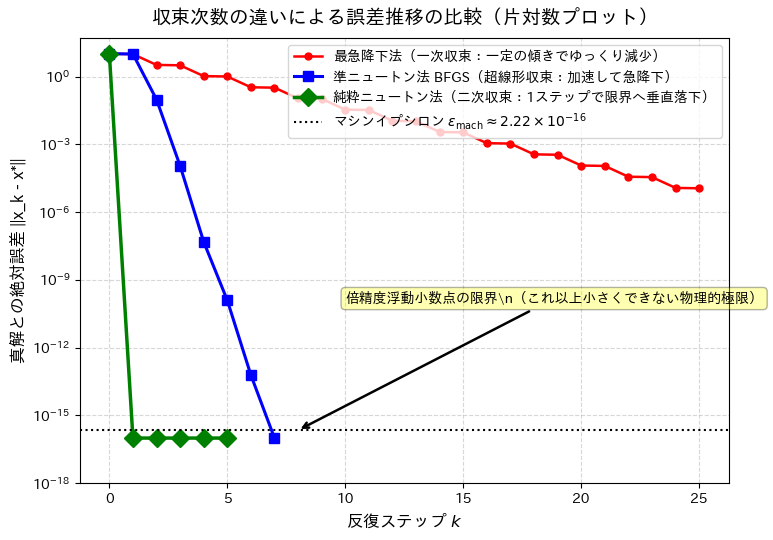

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib
from scipy.optimize import minimize

# 楕円谷問題 (条件数 kappa = 50)
def f_bench(v):
    return 0.5 * (v[0]**2 + 50.0 * v[1]**2)

def grad_bench(v):
    return np.array([v[0], 50.0 * v[1]], dtype=np.float64)

def hess_bench(v):
    return np.array([[1.0, 0.0], [0.0, 50.0]], dtype=np.float64)

x0 = np.array([10.0, 2.0], dtype=np.float64)
x_star = np.array([0.0, 0.0])

# 1. 最急降下法
errs_gd = [np.linalg.norm(x0)]
x = x0.copy()
for _ in range(25):
    g = grad_bench(x)
    H = hess_bench(x)
    eta = np.dot(g, g) / np.dot(g, H @ g)  # 最適学習率
    x = x - eta * g
    errs_gd.append(max(np.linalg.norm(x), 1e-16))

# 2. 純粋ニュートン法
errs_nt = [np.linalg.norm(x0)]
x = x0.copy()
for _ in range(5):
    g = grad_bench(x)
    H = hess_bench(x)
    p = np.linalg.solve(H, -g)
    x = x + p
    errs_nt.append(max(np.linalg.norm(x), 1e-16))

# 3. SciPy BFGS
scipy_errs = [np.linalg.norm(x0)]
def cb(xk):
    scipy_errs.append(max(np.linalg.norm(xk), 1e-16))

res = minimize(f_bench, x0, method='BFGS', jac=grad_bench, callback=cb, options={'gtol': 1e-16})

print("=== 収束精度の比較対決 ===")
print(f"最急降下法 (25反復後): 誤差 = {errs_gd[-1]:.4e}")
print(f"SciPy BFGS ({len(scipy_errs)-1}反復後): 誤差 = {scipy_errs[-1]:.4e}")
print(f"純粋ニュートン法 (1反復後): 誤差 = {errs_nt[1]:.4e}")

# 可視化：誤差の収束スピード比較
fig, ax = plt.subplots(figsize=(8, 5.5))

ax.semilogy(range(len(errs_gd)), errs_gd, 'r-o', lw=1.8, markersize=5, label='最急降下法（一次収束：一定の傾きでゆっくり減少）')
ax.semilogy(range(len(scipy_errs)), scipy_errs, 'b-s', lw=2.2, markersize=7, label='準ニュートン法 BFGS（超線形収束：加速して急降下）')
ax.semilogy(range(len(errs_nt)), errs_nt, 'g-D', lw=2.5, markersize=9, label='純粋ニュートン法（二次収束：1ステップで限界へ垂直落下）')

eps_mach = 2.220446049250313e-16
ax.axhline(eps_mach, color='black', linestyle=':', lw=1.5, label=r'マシンイプシロン $\epsilon_{\mathrm{mach}} \approx 2.22 \times 10^{-16}$')
ax.annotate('倍精度浮動小数点の限界\\n（これ以上小さくできない物理的極限）',
            xy=(8, eps_mach), xytext=(10, 1e-10),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.8),
            fontsize=10, bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3))

ax.set_title('収束次数の違いによる誤差推移の比較（片対数プロット）', fontsize=14, pad=10)
ax.set_xlabel('反復ステップ $k$', fontsize=12)
ax.set_ylabel('真解との絶対誤差 ||x_k - x*||', fontsize=12)
ax.set_ylim(1e-18, 50)
ax.grid(True, which='both', linestyle='--', alpha=0.5)
ax.legend(fontsize=10, loc='upper right')

plt.tight_layout()
plt.show()

---
## 7. 実社会・データサイエンスへの応用：モデルパラメータの最適化

本章では、これまでに学んだ最適化手法が実社会のデータ分析や機械学習でどのように活用されているのかを体感します。

### 機械学習の「モデル学習」とは何か？
データサイエンスにおいて、モデルを学習させるプロセスとは、本質的に **「損失関数（Loss Function）を最小化するパラメータ $\mathbf{w}$ を探す最適化問題」** に他なりません。

例えば、2次元平面上に散らばる 2 つのグループ（クラス 0 とクラス 1）を直線で分割する分類問題を考えます：
- モデルのパラメータ：境界線の傾きや位置を決める重み $w_1, w_2$ とバイアス $b$
- 目的関数：データ点とのズレを表す損失関数 $L(w_1, w_2, b)$

損失関数はお椀型（凸関数）になっている場合、ニュートン法や準ニュートン法（BFGS）を使えば、曲率を活かしてわずか数ステップで理想的な境界線（最適パラメータ）が一撃で求まります。最急降下法と BFGS 法で、その決定速度と滑らかさを比較してみましょう！

=== 分類パラメータ最適化の結果 ===
最急降下法 (50ステップ後): 損失 = 2.1847
BFGS 法   (28ステップ後): 損失 = 0.0000
求まった決定境界パラメータ: w1=32.600, w2=26.633, b=-3.026


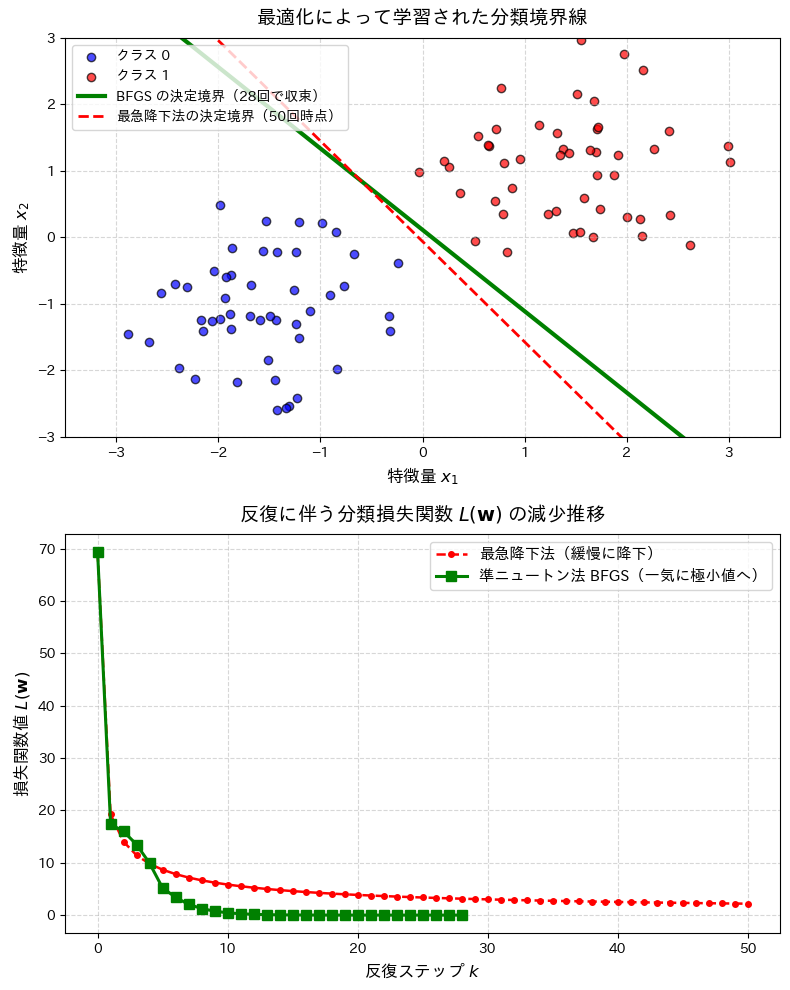

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib
from scipy.optimize import minimize

# 1. 2クラス分類データの生成
np.random.seed(42)
N = 100
# クラス0 (中心 [-1.5, -1.0])
X0 = np.random.randn(N // 2, 2) * 0.8 + np.array([-1.5, -1.0])
# クラス1 (中心 [1.5, 1.0])
X1 = np.random.randn(N // 2, 2) * 0.8 + np.array([1.5, 1.0])

X = np.vstack([X0, X1])
y = np.array([-1.0] * (N // 2) + [1.0] * (N // 2))  # ラベル -1, +1

# 2. 滑らかな分類損失関数（凸関数）
# L(w) = sum log(1 + exp(-y_i * (w1*x1 + w2*x2 + b)))
def loss_fn(params):
    w = params[:2]
    b = params[2]
    margins = y * (X @ w + b)
    # オーバーフロー防止
    return np.sum(np.log1p(np.exp(-np.clip(margins, -30, 30))))

def loss_grad(params):
    w = params[:2]
    b = params[2]
    margins = y * (X @ w + b)
    probs = 1.0 / (1.0 + np.exp(np.clip(margins, -30, 30)))  # 誤分類の度合い
    grad_w = - (X.T @ (y * probs))
    grad_b = - np.sum(y * probs)
    return np.append(grad_w, grad_b)

# 3. 最適化：最急降下法 vs 準ニュートン法（BFGS）
w_init = np.array([0.0, 0.0, 0.0])

# 最急降下法
w_gd = w_init.copy()
losses_gd = [loss_fn(w_gd)]
for _ in range(50):
    g = loss_grad(w_gd)
    w_gd -= 0.01 * g
    losses_gd.append(loss_fn(w_gd))

# BFGS法
losses_bfgs = [loss_fn(w_init)]
def cb(wk):
    losses_bfgs.append(loss_fn(wk))
res_bfgs = minimize(loss_fn, w_init, method='BFGS', jac=loss_grad, callback=cb)
w_bfgs = res_bfgs.x

print("=== 分類パラメータ最適化の結果 ===")
print(f"最急降下法 (50ステップ後): 損失 = {losses_gd[-1]:.4f}")
print(f"BFGS 法   ({len(losses_bfgs)-1}ステップ後): 損失 = {losses_bfgs[-1]:.4f}")
print(f"求まった決定境界パラメータ: w1={w_bfgs[0]:.3f}, w2={w_bfgs[1]:.3f}, b={w_bfgs[2]:.3f}")

# 可視化：縦配置 2 パネル
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10))

# 上図：データ点と学習された決定境界線
ax1.scatter(X0[:, 0], X0[:, 1], color='blue', alpha=0.7, edgecolors='k', label='クラス 0')
ax1.scatter(X1[:, 0], X1[:, 1], color='red', alpha=0.7, edgecolors='k', label='クラス 1')

# 決定境界 w1*x + w2*y + b = 0 => y = -(w1*x + b) / w2
x_line = np.linspace(-3.5, 3.5, 100)
y_line_bfgs = -(w_bfgs[0] * x_line + w_bfgs[2]) / w_bfgs[1]
y_line_gd = -(w_gd[0] * x_line + w_gd[2]) / w_gd[1]

ax1.plot(x_line, y_line_bfgs, 'g-', lw=3, label=f'BFGS の決定境界（{len(losses_bfgs)-1}回で収束）')
ax1.plot(x_line, y_line_gd, 'r--', lw=2, label='最急降下法の決定境界（50回時点）')

ax1.set_title('最適化によって学習された分類境界線', fontsize=14, pad=10)
ax1.set_xlabel('特徴量 $x_1$', fontsize=12)
ax1.set_ylabel('特徴量 $x_2$', fontsize=12)
ax1.set_xlim(-3.5, 3.5)
ax1.set_ylim(-3.0, 3.0)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10, loc='upper left')

# 下図：損失関数の減少推移
ax2.plot(range(len(losses_gd)), losses_gd, 'r--o', lw=1.8, markersize=4, label='最急降下法（緩慢に降下）')
ax2.plot(range(len(losses_bfgs)), losses_bfgs, 'g-s', lw=2.2, markersize=7, label='準ニュートン法 BFGS（一気に極小値へ）')

ax2.set_title('反復に伴う分類損失関数 $L(\\mathbf{w})$ の減少推移', fontsize=14, pad=10)
ax2.set_xlabel('反復ステップ $k$', fontsize=12)
ax2.set_ylabel('損失関数値 $L(\\mathbf{w})$', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()

---
## 8. これまでの学びとの関連

今回学んだ「最適化におけるニュートン法」は、これまでに学んできたアルゴリズムの基礎と深く関連しています。

---

### 1. 第1回（アルゴリズムの基礎・計算量と誤差）との繋がり
- **計算量の見積もり（$O(d)$ vs $O(d^3)$）**:  
  第1回で学んだ計算量（オーダー記法）。最急降下法の1反復が $O(d)$（極めて軽量）であるのに対し、純粋ニュートン法の1反復が $O(d^3)$（極めて重い）であるという劇的な格差は、まさに第1回で学んだアルゴリズム評価の真髄です。
- **マシンイプシロン（浮動小数点の限界）**:  
  第1回で学んだ倍精度浮動小数点（float64）の物理的限界 $\epsilon_{\text{mach}} \approx 2.22 \times 10^{-16}$。二次収束を達成したニュートン法は、この限界値にわずか数ステップで到達します。また、ヘッセ行列が平坦な場合に生じる「桁落ち・特異行列」も、第1回の有限精度の議論と直結しています。

---

### 2. 第2回（二分法）との繋がり
- **1次情報の堅実さ vs 2次情報のスピード**:  
  第2回で学んだ二分法は、符号の変化（正負）だけを頼りに解の区間を半分ずつ縮める手法でした（1次収束：公比 $1/2$）。絶対に失敗しない安心感がある一方、収束は極めて緩慢でした。  
  今回の「最急降下法（1次情報：足元の傾きだけ）」と「ニュートン法（2次情報：お椀の曲がり具合）」の関係も、これと全く同じ構図です。傾きだけに頼ると歩幅の調整に苦しみながらゆっくり進むのに対し、曲率を活用すると一気に最適解を射抜きます。

---

### 3. 第3回（ニュートン法(1)：方程式の数値解法）との繋がり
- **求根アルゴリズムから最適化への数学的接続**:  
  第3回では、関数 $f(x) = 0$ の根を「接線（1次近似）」によって探索しました：
  $$x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)}$$
  第7回（今回）では、関数の最小化問題 $\min f(x)$ が、導関数の停留点を求める方程式 $g(x) = f'(x) = 0$ と等価であることから：
  $$x_{k+1} = x_k - \frac{g(x_k)}{g'(x_k)} = x_k - \frac{f'(x_k)}{f''(x_k)}$$
  へと自然に発展しました。多次元空間では、分子が「勾配ベクトル $\nabla f$」、分母が「ヘッセ行列 $H = \nabla^2 f$」に対応し、第3回の手法が多次元最適化へと完全な昇華を遂げています。

---

### 4. 第5回（最急降下法）との繋がり
- **傾きのジグザグを「曲率の座標変換」で解決**:  
  第5回で学んだ最急降下法 $\mathbf{x}_{k+1} = \mathbf{x}_k - \eta \nabla f$ は、等高線に直交する最も急な坂を下る手法でした。しかし、方向によって傾きのきつさが異なる「細長い楕円谷」では、谷の壁の間を行き来する激しいジグザグ現象が発生しました。  
  今回のニュートン法は、ヘッセ行列 $H$ という「曲率の歪みを直す座標変換器」を挟み込むことで、楕円谷を真円へと補正し、ジグザグを起こさず最短ルートでお椀の底へジャンプできることを実証しました。